

# Simulación de portafolios

Diego Dueñas Martín
exp: 751426
11/11/2026

- **Parte 1:** portafolios con NVDA, BIMBO, CEMEX y AZN. Simulamos el precio final de cada activo (y del dólar, para pasar todo a pesos) y comparamos tres portafolios.
- **Parte 2:** AAPL, MSFT y NVDA. Medimos su correlación y generamos escenarios correlacionados con la descomposición de Cholesky.
- **Parte 3:** la tarea. Repetimos las dos partes anteriores comparando el caso independiente contra el correlacionado.

</div>

In [55]:
import yfinance as yf
import numpy as np 
import matplotlib.pyplot as plt



## Parte 1. NVDA, BIMBO, CEMEX y AZN

Supuesto de esta parte: cada activo se simula con su propio ruido aleatorio, **sin correlación entre ellos**. La Parte 2 muestra cómo incorporarla con Cholesky.





### 1.1 Traer los datos

Descargamos precios históricos de las cuatro acciones y del dólar en pesos (`USDMXN=X`, pesos por dólar). Con esto estimaremos cómo se ha movido cada serie.


In [56]:
tickers = ['NVDA', 'BIMBOA.MX', 'CEMEXCPO.MX', 'AZN']
fx_ticker = 'USDMXN=X'  # MXN por USD
prices = yf.download(tickers + [fx_ticker], start='2023-11-01', end='2026-11-01')['Close']

[*********************100%***********************]  5 of 5 completed




### 1.2 Definir la inversión inicial

Fijamos el capital (`V_o`, en MXN), los precios iniciales y el tipo de cambio inicial. NVDA y AZN cotizan en dólares; Bimbo y Cemex, en pesos. `usd_assets` marca cuáles hay que convertir para poder expresar todo el portafolio en MXN.


In [57]:
S0_fx = 18.58  # tipo de cambio inicial, MXN por USD
V_o = 100000  # capital inicial en MXN
n_simulations = 10000
s0_nvda = 202.06
s0_bimbo = 66.18
s0_cemex = 20.23
s0_azn = 186.58
S0 = np.array([s0_nvda, s0_bimbo, s0_cemex, s0_azn])

s0_nvda_mxn = s0_nvda * S0_fx
s0_azn_mxn = s0_azn * S0_fx





### 1.3 Medir el movimiento histórico

Calculamos los rendimientos logarítmicos diarios, $\ln(P_t / P_{t-1})$, y estimamos su media y su volatilidad anualizadas: la media se multiplica por 252 días hábiles y la desviación estándar por $\sqrt{252}$.



In [58]:
# Rendimientos logarítmicos diarios (acciones y USD/MXN) y estimaciones anualizadas
log_returns = np.log(prices[tickers + [fx_ticker]] / prices[tickers + [fx_ticker]].shift(1)).dropna()
mean_i = log_returns.mean() * 252
std_i = log_returns.std(ddof=1) * np.sqrt(252)

print('Media anual de rendimientos logarítmicos:')
print(mean_i)
print('\nDesviación estándar anual:')
print(std_i)
print('\nPrecios iniciales S0:', dict(zip(tickers, S0)))
print('Tipo de cambio inicial USD/MXN:', S0_fx)
print('Capital inicial V_o (MXN):', V_o)

Media anual de rendimientos logarítmicos:
Ticker
NVDA           0.704807
BIMBOA.MX     -0.058189
CEMEXCPO.MX    0.191209
AZN            0.152271
USDMXN=X       0.082993
dtype: float64

Desviación estándar anual:
Ticker
NVDA           0.468572
BIMBOA.MX      0.297780
CEMEXCPO.MX    0.330266
AZN            0.251216
USDMXN=X       0.109810
dtype: float64

Precios iniciales S0: {'NVDA': np.float64(202.06), 'BIMBOA.MX': np.float64(66.18), 'CEMEXCPO.MX': np.float64(20.23), 'AZN': np.float64(186.58)}
Tipo de cambio inicial USD/MXN: 18.58
Capital inicial V_o (MXN): 100000




### 1.4 Simulación sencilla

Simulamos el precio de cada activo a un año con

$$S_T = S_0 \exp\Big[\big(m - \tfrac{\sigma^2}{2}\big)T + \sigma\sqrt{T}\,Z\Big], \qquad Z \sim N(0,1)$$

donde $m$ y $\sigma$ son la media y la desviación anuales de la sección 1.3. El tipo de cambio se simula igual, para poder expresar los activos en pesos. Cada activo usa su propio $Z$, es decir, se simulan de forma independiente.


In [59]:
# Simulacion sencilla de precios a un ano para cada activo.
T = 1
M = 10000

Z_nvda = np.random.normal(0, 1, M)
ST_nvda = s0_nvda * np.exp((mean_i["NVDA"] - std_i["NVDA"]**2 / 2) * T + std_i["NVDA"] * np.sqrt(T) * Z_nvda)

Z_cemex = np.random.normal(0, 1, M)
ST_cemex = s0_cemex * np.exp((mean_i["CEMEXCPO.MX"] - std_i["CEMEXCPO.MX"]**2 / 2) * T + std_i["CEMEXCPO.MX"] * np.sqrt(T) * Z_cemex)

Z_bmb = np.random.normal(0, 1, M)
ST_bmb = s0_bimbo * np.exp((mean_i["BIMBOA.MX"] - std_i["BIMBOA.MX"]**2 / 2) * T + std_i["BIMBOA.MX"] * np.sqrt(T) * Z_bmb)

Z_azn = np.random.normal(0, 1, M)
ST_azn = s0_azn * np.exp((mean_i["AZN"] - std_i["AZN"]**2 / 2) * T + std_i["AZN"] * np.sqrt(T) * Z_azn)

Z_fx = np.random.normal(0, 1, M)
ST_fx = S0_fx * np.exp((mean_i[fx_ticker] - std_i[fx_ticker]**2 / 2) * T + std_i[fx_ticker] * np.sqrt(T) * Z_fx)



### 1.5 Precios terminales en pesos

Juntamos los precios simulados en una sola matriz (una columna por activo, una fila por escenario) y convertimos a MXN los que cotizan en dólares, multiplicando por el tipo de cambio simulado **del mismo escenario**.

*Corrección:* la versión anterior de esta celda multiplicaba por el precio inicial en pesos en vez de por el tipo de cambio simulado (`ST_fx` se simulaba y nunca se usaba). Eso inflaba el valor terminal por un factor igual al precio inicial de cada activo, y por eso los rendimientos salían en decenas de miles de por ciento.



In [60]:
S_T_activos = np.column_stack([ST_nvda, ST_bmb, ST_cemex, ST_azn])

# NVDA y AZN cotizan en dólares: se multiplican por el tipo de cambio simulado del MISMO escenario.
# BIMBO y CEMEX ya están en pesos: se multiplican por 1.
S_T_mxn = S_T_activos * np.column_stack([ST_fx, np.ones(M), np.ones(M), ST_fx])



### 1.6 Armar los portafolios

Cada fila de `pesos` es un portafolio. Con el dinero asignado a cada activo calculamos cuántas acciones **enteras** se pueden comprar:

$$N_i = \left\lfloor \frac{V_{o,i}}{P_{i,0}} \right\rfloor$$

Lo que no alcanza para otra acción se queda como `efectivo`, y el valor terminal de cada portafolio es

$$V_T = \sum_i N_i \, S_{T,i} + \text{efectivo}$$

Por eso el peso real puede quedar un poco distinto del planeado, sobre todo en acciones caras como NVDA y AZN.


In [61]:
# Cada fila representa un portafolio; cada columna, la inversión en un ticker.
pesos = np.array([
    [1, 0, 0, 0],
    [.25, .25, .25, .25],
    [.1, .2, .3, .4]
])
nombres_portafolios = ['100% NVDA', '25% cada activo', '10% NVDA / 20% BIMBO / 30% CEMEX / 40% AZN']
precios_iniciales_mxn = np.array([
    s0_nvda * S0_fx,
    s0_bimbo,
    s0_cemex,
    s0_azn * S0_fx
])
V_oi = pesos * V_o
N_i = np.floor(V_oi / precios_iniciales_mxn + 1e-9).astype(int)
efectivo = V_o - (N_i * precios_iniciales_mxn).sum(axis=1)
vt_i = N_i[:, :, None] * S_T_mxn.T[None, :, :]
vt = vt_i.sum(axis=1) + efectivo[:, None]



### 1.7 Distribución de precios por activo

Comparamos los precios terminales simulados en MXN con el precio inicial de cada activo (línea punteada).


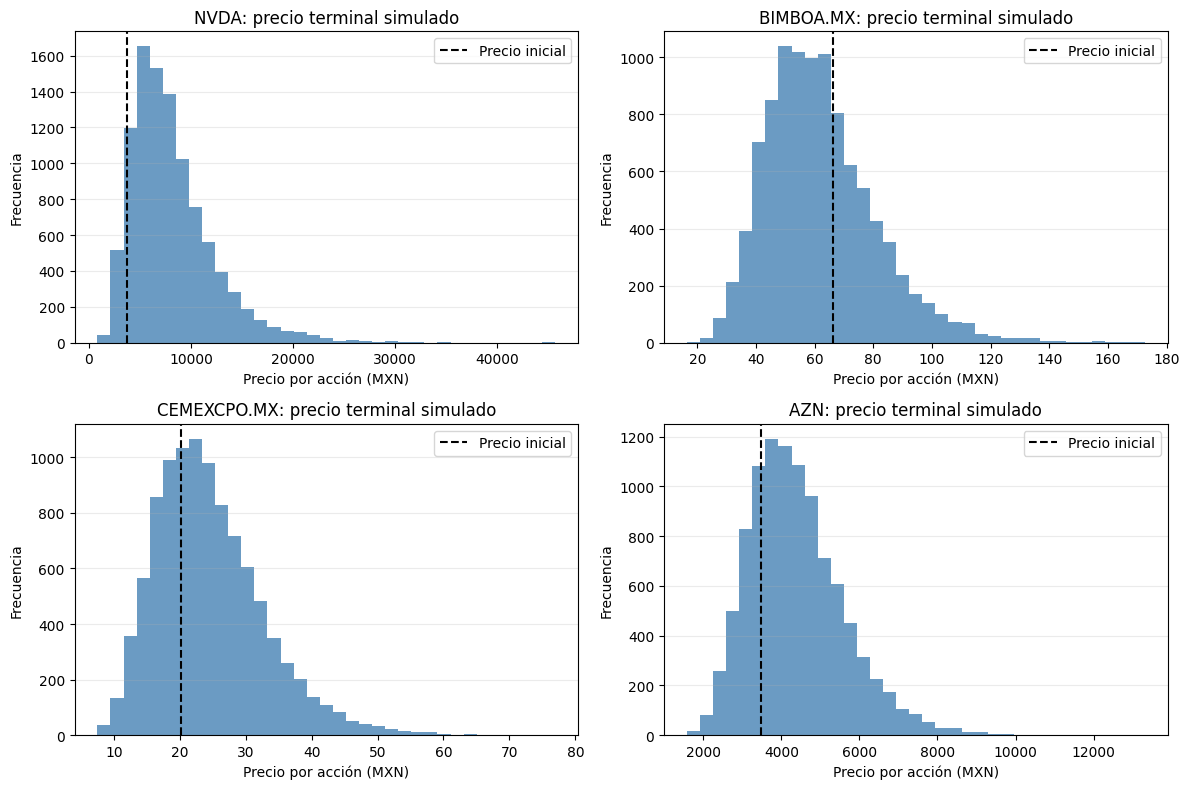

In [62]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for i, ax in enumerate(axes.flat):
    ax.hist(S_T_mxn[:, i], bins=35, color='steelblue', alpha=0.8)
    ax.axvline(precios_iniciales_mxn[i], color='black', linestyle='--', label='Precio inicial')
    ax.set(title=f'{tickers[i]}: precio terminal simulado', xlabel='Precio por acción (MXN)', ylabel='Frecuencia')
    ax.legend()
    ax.grid(axis='y', alpha=0.25)
plt.tight_layout()
plt.show()



### 1.8 Comparar rendimientos y portafolios

El diagrama de caja resume los rendimientos simulados por activo (sin dibujar los valores atípicos); el histograma compara el valor terminal de las tres combinaciones de inversión.


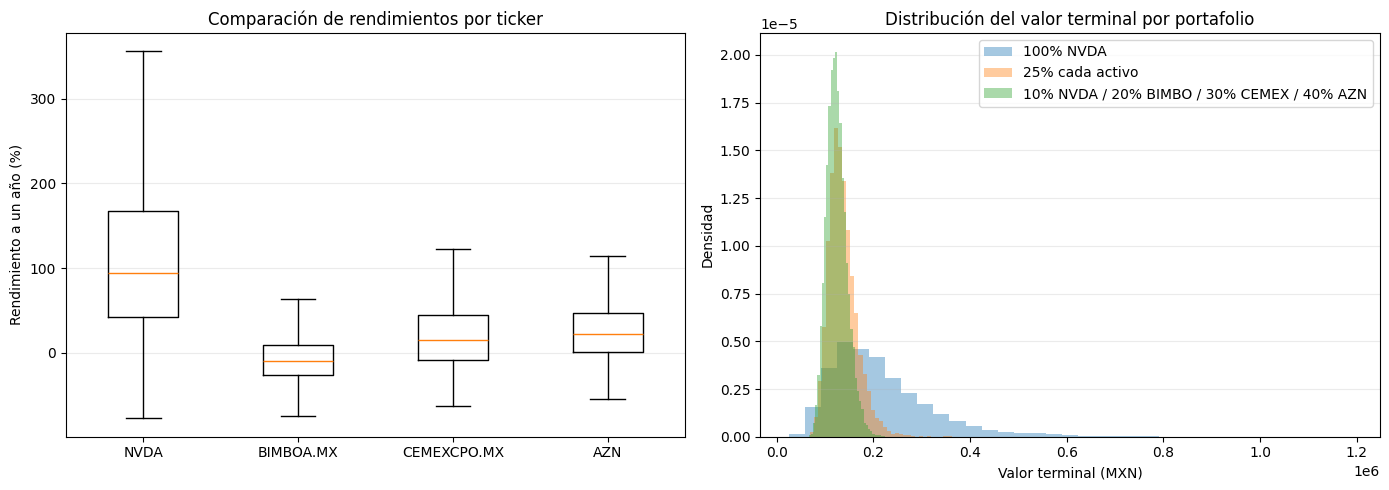

In [63]:
rendimientos_pct = (S_T_mxn / precios_iniciales_mxn - 1) * 100
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].boxplot([rendimientos_pct[:, i] for i in range(len(tickers))], tick_labels=tickers, showfliers=False)
axes[0].set(title='Comparación de rendimientos por ticker', ylabel='Rendimiento a un año (%)')
axes[0].grid(axis='y', alpha=0.25)
for i, nombre in enumerate(nombres_portafolios):
    axes[1].hist(vt[i], bins=35, density=True, alpha=0.4, label=nombre)
axes[1].set(title='Distribución del valor terminal por portafolio', xlabel='Valor terminal (MXN)', ylabel='Densidad')
axes[1].legend()
axes[1].grid(axis='y', alpha=0.25)
plt.tight_layout()
plt.show()



### 1.9 Resumen de resultados

Mostramos la inversión inicial, el número de acciones compradas y el valor terminal medio con su variabilidad.

Los resultados por ticker invierten todo `V_o` en un solo activo con acciones **fraccionarias**; los portafolios usan acciones **enteras más efectivo**. Por eso "100% NVDA" no coincide exactamente con NVDA individual.


In [64]:
print('Inversión inicial por activo V_oi (MXN):')
print(dict(zip(nombres_portafolios, V_oi)))
print('\nAcciones compradas N_i por portafolio y ticker:')
print(dict(zip(nombres_portafolios, N_i)))
print('\nResultados individuales por ticker (invirtiendo todo V_o en cada uno):')
for i, ticker in enumerate(tickers):
    vt_ticker = V_o * S_T_mxn[:, i] / precios_iniciales_mxn[i]
    print(f'{ticker}: valor terminal medio = MXN {vt_ticker.mean():,.2f}; desviación = MXN {vt_ticker.std(ddof=1):,.2f}; rendimiento medio = {(vt_ticker.mean() / V_o - 1) * 100:.2f}%')
print('\nResultados por portafolio: valor terminal medio, desviación estándar y rendimiento medio:')
for i, nombre in enumerate(nombres_portafolios):
    media = vt[i].mean()
    print(f'{nombre}: media = MXN {media:,.2f}; desviación = MXN {vt[i].std(ddof=1):,.2f}; rendimiento = {(media / V_o - 1) * 100:.2f}%')

Inversión inicial por activo V_oi (MXN):
{'100% NVDA': array([100000.,      0.,      0.,      0.]), '25% cada activo': array([25000., 25000., 25000., 25000.]), '10% NVDA / 20% BIMBO / 30% CEMEX / 40% AZN': array([10000., 20000., 30000., 40000.])}

Acciones compradas N_i por portafolio y ticker:
{'100% NVDA': array([26,  0,  0,  0]), '25% cada activo': array([   6,  377, 1235,    7]), '10% NVDA / 20% BIMBO / 30% CEMEX / 40% AZN': array([   2,  302, 1482,   11])}

Resultados individuales por ticker (invirtiendo todo V_o en cada uno):
NVDA: valor terminal medio = MXN 217,491.63; desviación = MXN 110,746.93; rendimiento medio = 117.49%
BIMBOA.MX: valor terminal medio = MXN 93,941.47; desviación = MXN 28,606.99; rendimiento medio = -6.06%
CEMEXCPO.MX: valor terminal medio = MXN 121,135.94; desviación = MXN 40,809.18; rendimiento medio = 21.14%
AZN: valor terminal medio = MXN 126,619.15; desviación = MXN 35,288.61; rendimiento medio = 26.62%

Resultados por portafolio: valor terminal medio, 



## Parte 2. AAPL, MSFT y NVDA

Aquí vemos cómo generar escenarios **correlacionados**: de la covarianza histórica se obtiene la matriz `L` (Cholesky) y con ella se convierten normales independientes en normales con la correlación de los datos.




### 2.1 Datos y matriz de correlación

Descargamos los precios de AAPL, MSFT y NVDA y calculamos la correlación histórica de sus rendimientos diarios porcentuales.

In [65]:
tickers_corr = ['AAPL', 'MSFT', 'NVDA']
precios_corr = yf.download(tickers_corr, start='2023-11-01', end='2026-11-01')['Close']
correlation_matrix = precios_corr.pct_change().corr()
print(correlation_matrix.round(4))

[*********************100%***********************]  3 of 3 completed

Ticker    AAPL    MSFT    NVDA
Ticker                        
AAPL    1.0000  0.3361  0.2904
MSFT    0.3361  1.0000  0.4226
NVDA    0.2904  0.4226  1.0000



### 2.2 Matriz de covarianza

Calculamos los rendimientos logarítmicos de AAPL, MSFT y NVDA. `Sigma` es su covarianza anualizada (covarianza diaria × 252) y `media` contiene los rendimientos medios anualizados.
    

In [66]:
rendimientos_corr = np.log(precios_corr / precios_corr.shift(1)).dropna()
Sigma = (rendimientos_corr.cov() * 252).to_numpy()
media = (rendimientos_corr.mean() * 252).to_numpy()

print('Matriz de covarianza anualizada:')
print(Sigma)
print('Media anualizada:')
print(media)

Matriz de covarianza anualizada:
[[0.0711895  0.02311266 0.03532508]
 [0.02311266 0.06716448 0.05090351]
 [0.03532508 0.05090351 0.21677918]]
Media anualizada:
[0.23388784 0.14563166 0.52978937]




### 2.3 Descomposición de Cholesky

Obtenemos la matriz triangular inferior `L` que cumple

$$\Sigma = L \, L^{T}$$

La comprobación `L @ L.T` debe devolver `Sigma`.


In [67]:
L = np.linalg.cholesky(Sigma)
print(L)
print('Comprobacion L @ L.T:')
print(L @ L.T)

[[0.2668136  0.         0.        ]
 [0.08662473 0.24425526 0.        ]
 [0.1323961  0.16144888 0.41615468]]
Comprobacion L @ L.T:
[[0.0711895  0.02311266 0.03532508]
 [0.02311266 0.06716448 0.05090351]
 [0.03532508 0.05090351 0.21677918]]




### 2.4 Simular epsilon

Generamos vectores de normales estándar **independientes**: cada columna es un escenario y cada fila corresponde a un ticker.


In [68]:
n_simulaciones_corr = 10000
epsilon = np.random.normal(0, 1, size=(len(tickers_corr), n_simulaciones_corr))



### 2.5 Transformar a la normal multivariada

Transformamos cada vector con

$$Z = \text{media} + L \, \varepsilon$$

Los escenarios resultantes tienen media `media` y matriz de covarianza `Sigma`. La verificación compara la media y la covarianza simuladas con las originales; no son idénticas porque son 10,000 escenarios y no infinitos.


In [69]:
Z = 0 + L @ epsilon
print('Dimensiones de Z (tickers x escenarios):', Z.shape)
print('Media simulada por ticker:')
print(Z.mean(axis=1))
print('Covarianza simulada:')
print(np.cov(Z))

Dimensiones de Z (tickers x escenarios): (3, 10000)
Media simulada por ticker:
[0.00357213 0.00092447 0.00396149]
Covarianza simulada:
[[0.07307102 0.02401512 0.03796589]
 [0.02401512 0.06620378 0.05125408]
 [0.03796589 0.05125408 0.22328454]]




### 2.6 Precios terminales de AAPL, MSFT y NVDA

`Z` ya trae el rendimiento logarítmico a un año de cada escenario, con la tendencia y la correlación de los datos. Para pasar a precios lo aplicamos al precio inicial `S0_corr`, que es el último cierre descargado:

$$S_T = S_0 \, e^{Z}$$

No se resta $\sigma^2/2$ porque `media` ya es la media de los log-rendimientos. El resultado `ST_corr` tiene forma (3, 10000): una fila por ticker y una columna por escenario, en el mismo orden que `Z`. Al final imprimimos el precio inicial, el precio terminal medio y su desviación para cada activo.


In [70]:
# Precio inicial de cada activo: último cierre descargado (mismo orden que Sigma, media y Z)
S0_corr = precios_corr.iloc[-1].to_numpy()

# Precio a un año: Z ya trae el rendimiento logarítmico anual de cada escenario
ST_corr = S0_corr[:, None] * np.exp(Z)   # forma (3, 10000): filas = tickers, columnas = escenarios

for i, t in enumerate(precios_corr.columns):
    print(f'{t}: S0 = {S0_corr[i]:,.2f} | ST medio = {ST_corr[i].mean():,.2f} | desviación = {ST_corr[i].std(ddof=1):,.2f}')

AAPL: S0 = 344.63 | ST medio = 358.73 | desviación = 98.68
MSFT: S0 = 521.91 | ST medio = 540.00 | desviación = 141.52
NVDA: S0 = 204.64 | ST medio = 229.83 | desviación = 115.83


### 2.7 Se realizan graficas
Una que nos muestra como se distribuyen nuestros datos(simulaciones).

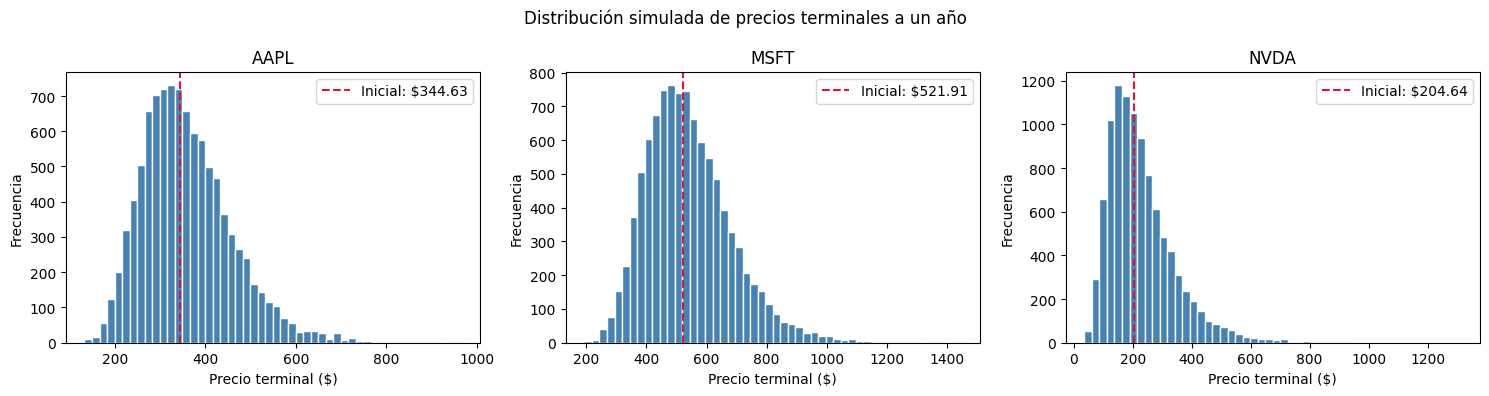

In [71]:
# Ganancia o pérdida al final de un año, suponiendo una acción de cada activo
ganancias_corr = ST_corr - S0_corr[:, None]
tickers = list(precios_corr.columns)

# Distribución simulada de precios terminales
fig, axes = plt.subplots(1, len(tickers), figsize=(15, 4))
for i, (ax, ticker) in enumerate(zip(axes, tickers)):
    ax.hist(ST_corr[i], bins=50, color="steelblue", edgecolor="white")
    ax.axvline(S0_corr[i], color="crimson", linestyle="--", label=f"Inicial: ${S0_corr[i]:,.2f}")
    ax.set(title=ticker, xlabel="Precio terminal ($)", ylabel="Frecuencia")
    ax.legend()
fig.suptitle("Distribución simulada de precios terminales a un año")
fig.tight_layout()
plt.show()




## Parte 3. Tarea: independencia contra correlación

Hasta aquí hay dos formas de simular. La Parte 1 le da a cada activo su propio ruido (independientes) y la Parte 2 usa Cholesky para que se muevan juntos (correlacionados). La tarea es ponerlas lado a lado.

### La idea central

La correlación **no cambia lo que le pasa a cada activo por separado**: la distribución de NVDA es la misma en las dos simulaciones. Lo que cambia es cómo se combinan dentro de un portafolio. Con pesos $w_i$, volatilidades $\sigma_i$ y correlaciones $\rho_{ij}$, la varianza del portafolio es

$$\operatorname{Var}(V) \;=\; \underbrace{\sum_i w_i^2\,\sigma_i^2}_{\text{cada activo por su lado}} \;+\; \underbrace{2\sum_{i<j} w_i\,w_j\,\sigma_i\,\sigma_j\,\rho_{ij}}_{\text{cómo se mueven juntos}}$$

Si son independientes, $\rho_{ij}=0$ y el segundo término desaparece. Si $\rho_{ij}>0$, ese término suma y el portafolio resulta más riesgoso de lo que parecía. Esta es la idea de diversificación de Markowitz: repartir el dinero baja el riesgo, pero solo en la medida en que los activos **no** se muevan igual.

### Cómo comparamos de forma justa

Los dos casos se simulan con los **mismos números aleatorios** $\varepsilon$. Solo cambia la forma de transformarlos:

$$\text{independientes: } Z_i = \sigma_i\,\varepsilon_i \qquad\qquad \text{correlacionados: } Z = L\,\varepsilon, \quad \Sigma = L\,L^{T}$$

Así, cualquier diferencia entre las dos distribuciones se debe a la correlación y no a la suerte del sorteo.

### 3.0 Funciones auxiliares

Tres funciones que se usan en las dos partes de la tarea: una gráfica comparativa, una tabla de resultados y una verificación con fórmulas exactas.



In [72]:
def graficar_comparacion(vt_ind, vt_cor, nombres, titulo):
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    for k, ax in enumerate(axes):
        bins = np.histogram_bin_edges(np.concatenate([vt_ind[k], vt_cor[k]]), bins=50)   # mismos bins para comparar
        ax.hist(vt_ind[k], bins=bins, density=True, alpha=0.5, label='Independientes')
        ax.hist(vt_cor[k], bins=bins, density=True, alpha=0.5, label='Correlacionados')
        ax.axvline(V_o, color='black', linestyle='--', label='Inversión inicial')
        ax.set(title=nombres[k], xlabel='Valor terminal (MXN)', ylabel='Densidad')
        ax.title.set_fontsize(10)
        ax.legend(fontsize=8)
    fig.suptitle(titulo)
    plt.tight_layout()
    plt.show()


def resumen_comparacion(vt_ind, vt_cor, nombres):
    for k, nombre in enumerate(nombres):
        for caso, v in [('Independientes', vt_ind[k]), ('Correlacionados', vt_cor[k])]:
            print(f'{nombre} | {caso:15s} | media {v.mean():>9,.0f} | desv. {v.std(ddof=1):>8,.0f} | P(perder) {(v < V_o).mean():.1%}')
        print()



## 3.1 Ejercicio A con correlación

Repetimos la Parte 1 (NVDA, BIMBO, CEMEX, AZN y el dólar), pero ahora los cinco factores se mueven con la correlación histórica. El dólar entra en la matriz porque NVDA y AZN se convierten a pesos con el tipo de cambio de **cada escenario**: su relación con el resto también forma parte del portafolio.

### Paso 1. Covarianza y correlación históricas

Usamos los mismos rendimientos logarítmicos de la sección 1.3 (`log_returns`):

$$\Sigma_A = 252 \cdot \operatorname{Cov}\big(\text{rendimientos diarios}\big) \qquad\qquad \rho_{ij} = \frac{\Sigma_{ij}}{\sigma_i\,\sigma_j}$$



In [73]:
activos_A = list(log_returns.columns)      # NVDA, BIMBOA.MX, CEMEXCPO.MX, AZN, USDMXN=X
Sigma_A = (log_returns.cov() * 252).to_numpy()    # covarianza anual de NVDA, BIMBO, CEMEX, AZN y USD/MXN
L_A = np.linalg.cholesky(Sigma_A)
print(log_returns.corr().round(3))

# epsilon independientes (M x 5) -> shocks correlacionados con L
Z_A = np.random.normal(0, 1, (M, 5)) @ L_A.T

S0_A = np.array([s0_nvda, s0_bimbo, s0_cemex, s0_azn, S0_fx])
ST_A = S0_A * np.exp((mean_i.to_numpy() - std_i.to_numpy()**2 / 2) * T + Z_A * np.sqrt(T))

# a pesos (igual que 1.5) y valor terminal de los 3 portafolios (igual que 1.6)
S_T_mxn_cor = ST_A[:, :4] * np.column_stack([ST_A[:, 4], np.ones(M), np.ones(M), ST_A[:, 4]])
vt_cor = N_i @ S_T_mxn_cor.T + efectivo[:, None]      # `vt` (sección 1.6) ya es el caso independiente

Ticker        NVDA  BIMBOA.MX  CEMEXCPO.MX    AZN  USDMXN=X
Ticker                                                     
NVDA         1.000      0.088        0.241 -0.001     0.006
BIMBOA.MX    0.088      1.000        0.211  0.106     0.061
CEMEXCPO.MX  0.241      0.211        1.000  0.097    -0.019
AZN         -0.001      0.106        0.097  1.000    -0.007
USDMXN=X     0.006      0.061       -0.019 -0.007     1.000



### Paso 2. Escenarios independientes y correlacionados

Para cada escenario sorteamos cinco normales estándar $\varepsilon$ y construimos los shocks de dos maneras:

$$\text{independientes: } Z_i = \sigma_i\,\varepsilon_i \qquad\qquad \text{correlacionados: } Z = L_A\,\varepsilon$$

Después aplicamos el mismo modelo de la sección 1.4 a cada activo,

$$S_{T,i} = S_{0,i}\,\exp\Big[\big(m_i - \tfrac{\sigma_i^2}{2}\big)T + Z_i\sqrt{T}\Big]$$

y la conversión a pesos de la sección 1.5: NVDA y AZN se multiplican por el dólar simulado del mismo escenario. Los portafolios son los de la sección 1.6, con las mismas acciones `N_i` y el mismo `efectivo`.



In [82]:
rng = np.random.default_rng(67)        
eps_A = rng.standard_normal((M, len(activos_A)))
sigma_A = np.sqrt(np.diag(Sigma_A))

Z_ind_A = eps_A * sigma_A                  #  ruido
Z_cor_A = eps_A @ L_A.T                    # ruido con la correlación histórica 

S0_A = np.array([s0_nvda, s0_bimbo, s0_cemex, s0_azn, S0_fx])
tendencia_A = (mean_i[activos_A].to_numpy() - sigma_A**2 / 2) * T


def precios_mxn_A(Z):
    ST = S0_A * np.exp(tendencia_A + Z * np.sqrt(T))        # (M, 5): NVDA, BIMBO, CEMEX, AZN, USDMXN
    return ST[:, :4] * np.column_stack([ST[:, 4], np.ones(M), np.ones(M), ST[:, 4]])   # a pesos


ST_mxn_ind = precios_mxn_A(Z_ind_A)
ST_mxn_cor = precios_mxn_A(Z_cor_A)

# Valor terminal de los tres portafolios de 1.6: V_T = N_i @ S_T + efectivo
vt_ind_A = N_i @ ST_mxn_ind.T + efectivo[:, None]
vt_cor_A = N_i @ ST_mxn_cor.T + efectivo[:, None]

nombres_A = ['Caso 1: 100% NVDA', 'Caso 2: 25% cada activo', 'Caso 3: 10% NVDA / 20% BIMBO / 30% CEMEX / 40% AZN']

print('Chequeo contra 1.6 (valor terminal medio, independientes):')
print('  sección 1.6  :', vt.mean(axis=1).round(0))
print('  esta sección :', vt_ind_A.mean(axis=1).round(0), ' (difieren solo por el azar del sorteo)')

Chequeo contra 1.6 (valor terminal medio, independientes):
  sección 1.6  : [214685. 136694. 124099.]
  esta sección : [214130. 136613. 124066.]  (difieren solo por el azar del sorteo)




### Paso 3. Distribución de los casos 1, 2 y 3

Los mismos tres portafolios de la sección 1.6. En cada gráfica, azul es el caso independiente y naranja el correlacionado. La línea punteada es lo que se invirtió.


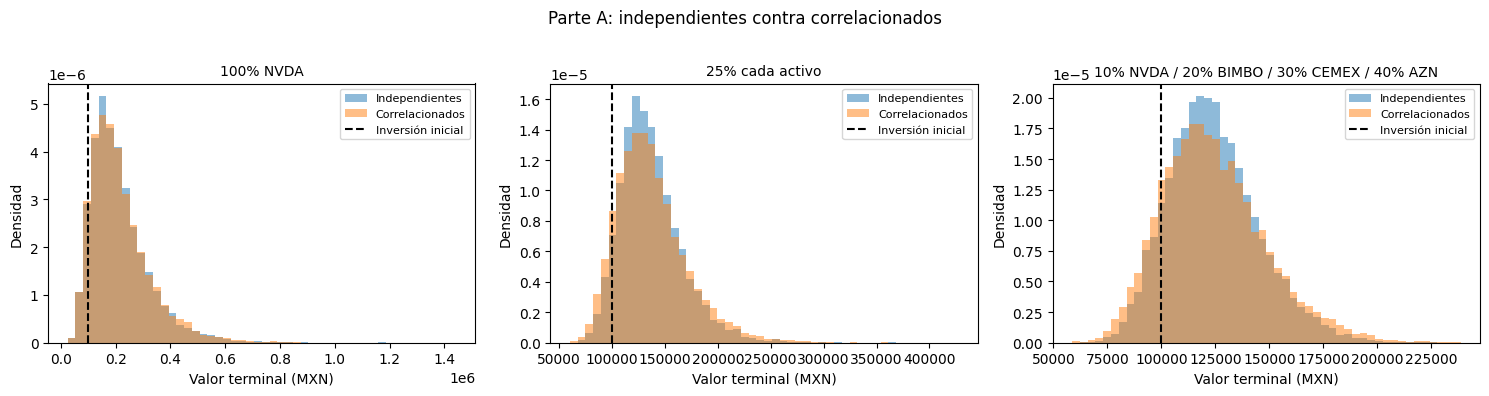

In [75]:
graficar_comparacion(vt, vt_cor, nombres_portafolios, 'Parte A: independientes contra correlacionados')


### Paso 4. Los números detrás de las gráficas

Para cada portafolio medimos cuatro cosas: la media, la desviación estándar, el percentil 5% (el valor por debajo del cual cae el 5% de los peores escenarios) y la probabilidad de terminar con menos de lo invertido.


In [76]:
resumen_comparacion(vt, vt_cor, nombres_portafolios)

100% NVDA | Independientes  | media   214,685 | desv.  108,101 | P(perder) 8.2%
100% NVDA | Correlacionados | media   217,344 | desv.  111,887 | P(perder) 8.1%

25% cada activo | Independientes  | media   136,694 | desv.   29,480 | P(perder) 6.9%
25% cada activo | Correlacionados | media   137,304 | desv.   33,849 | P(perder) 10.1%

10% NVDA / 20% BIMBO / 30% CEMEX / 40% AZN | Independientes  | media   124,099 | desv.   21,060 | P(perder) 11.6%
10% NVDA / 20% BIMBO / 30% CEMEX / 40% AZN | Correlacionados | media   124,214 | desv.   24,197 | P(perder) 14.9%





## 3.2 Ejercicio B con esquemas de inversión

Ahora la Parte 2 (AAPL, MSFT, NVDA) con 100,000 MXN. Usamos la misma `Sigma`, `media` y `L` de las secciones 2.2 y 2.3. El orden de los activos es el de `precios_corr.columns`, o sea **[AAPL, MSFT, NVDA]**:

| Esquema | AAPL | MSFT | NVDA |
|---|---|---|---|
| [1, 0, 0] | 100% | 0% | 0% |
| [0.33, 0.33, 0.34] | 33% | 33% | 34% |
| [0.2, 0.2, 0.6] | 20% | 20% | 60% |

El primer esquema es 100% **AAPL**, no NVDA como en la Parte 1. Dos decisiones que conviene tener claras:

- **Tipo de cambio fijo.** Compramos y valuamos con `S0_fx`. Así aislamos el efecto de la correlación entre las acciones; el riesgo cambiario, que en la Parte A sí entra, queda fuera de esta parte.
- **Tendencia.** Usamos `media` (el rendimiento logarítmico medio histórico), como dice el texto de la sección 2.5. Ojo: el código de esa celda usa 0 en lugar de `media`. Para ver el caso sin tendencia, cambia `tendencia_B = media` por `np.zeros(3)`; la conclusión sobre la correlación se mantiene.

### Paso 1. Cuántas acciones compra cada esquema

$$N_i = \left\lfloor \frac{w_i\,V_o}{P_{0,i}\,S_{0,fx}} \right\rfloor \qquad\qquad \text{efectivo} = V_o - \sum_i N_i\,P_{0,i}\,S_{0,fx}$$


In [77]:
assert list(precios_corr.columns) == ['AAPL', 'MSFT', 'NVDA']      # el orden de los esquemas depende de esto

pesos_B = np.array([[1, 0, 0],
                    [.33, .33, .34],
                    [.2, .2, .6]])
nombres_B = ['[1, 0, 0]  (100% AAPL)', '[0.33, 0.33, 0.34]', '[0.2, 0.2, 0.6]']

precio_mxn_B = S0_corr * S0_fx                                      # precio de una acción en MXN
N_B = np.floor(pesos_B * V_o / precio_mxn_B + 1e-9).astype(int)
efectivo_B = V_o - (N_B * precio_mxn_B).sum(axis=1)
print('Acciones [AAPL, MSFT, NVDA] por esquema:')
print(N_B)
print('Efectivo sobrante (MXN):', efectivo_B.round(0))

Acciones [AAPL, MSFT, NVDA] por esquema:
[[15  0  0]
 [ 5  3  8]
 [ 3  2 15]]
Efectivo sobrante (MXN): [3952. 8475. 4363.]



### Paso 2. Escenarios independientes y correlacionados

Igual que en el Paso 2 de la Parte A, con los mismos $\varepsilon$ en los dos casos:

$$\text{independientes: } Z_i = \sigma_i\,\varepsilon_i \qquad\quad \text{correlacionados: } Z = L\,\varepsilon \qquad\quad S_{T,i} = S_{0,i}\,e^{\,\mu_i + Z_i}$$

Como `media` ya es la media de los log-rendimientos, no se resta $\sigma^2/2$ (es lo que dice la sección 2.6).



In [81]:
rng = np.random.default_rng(42)
eps = rng.standard_normal((3, n_simulaciones_corr))
sigma = np.sqrt(np.diag(Sigma))

ST_ind_B = S0_corr[:, None] * np.exp(media[:, None] + sigma[:, None] * eps)   # independientes
ST_cor_B = S0_corr[:, None] * np.exp(media[:, None] + L @ eps)                # correlacionados (Cholesky)

vt_ind_B = N_B @ (ST_ind_B * S0_fx) + efectivo_B[:, None]
vt_cor_B = N_B @ (ST_cor_B * S0_fx) + efectivo_B[:, None]



### Paso 3. Distribución de los tres esquemas

Las mismas gráficas de la Parte A: azul independientes, naranja correlacionados, línea punteada en lo invertido.


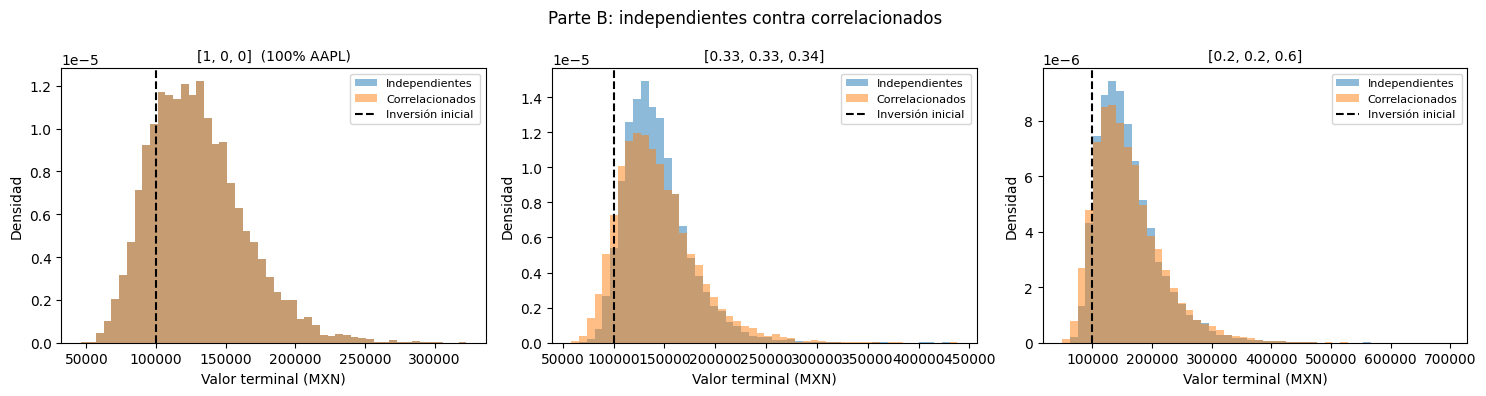

In [79]:
graficar_comparacion(vt_ind_B, vt_cor_B, nombres_B, 'Parte B: independientes contra correlacionados')


### Paso 4. Los números detrás de las gráficas

Las mismas cuatro medidas de la Parte A.


In [80]:
resumen_comparacion(vt_ind_B, vt_cor_B, nombres_B)

[1, 0, 0]  (100% AAPL) | Independientes  | media   129,674 | desv.   34,173 | P(perder) 19.8%
[1, 0, 0]  (100% AAPL) | Correlacionados | media   129,674 | desv.   34,173 | P(perder) 19.8%

[0.33, 0.33, 0.34] | Independientes  | media   142,735 | desv.   32,098 | P(perder) 4.6%
[0.33, 0.33, 0.34] | Correlacionados | media   142,752 | desv.   38,483 | P(perder) 9.9%

[0.2, 0.2, 0.6] | Independientes  | media   160,570 | desv.   54,326 | P(perder) 7.0%
[0.2, 0.2, 0.6] | Correlacionados | media   160,612 | desv.   58,517 | P(perder) 10.3%

